# Notebook 2 of 2 — Pretrained GridSFM KILLGEN predictions + generator-level exact SHAP

**Run the KILLGEN sampling notebook first.** This notebook uses **only GridSFM** to predict feasible/infeasible and SHAP to explain which **switched-off generator(s)** most influenced that prediction. **It never calls Julia** and never treats solver `accepted` labels as model predictions.

**Important GridSFM schema detail:** there is *no `gen_status` input column*. The official exporter represents an OFF generator by **omitting its generator node and both generator_link edge directions**, then reindexing the surviving generator nodes. This notebook does exactly that, using `metadata.gen_id_map` to establish safe generator-ID alignment. <https://github.com/microsoft/GridSFM/blob/main/power_grid/US/topology_solver_pipeline/export_gridsfm_data.jl>

Candidate SHAP attribution is **generator-level**, not Pd/Qd. Positive SHAP values increase the chosen target class probability (feasible or infeasible), while negative values decrease it. They describe *model behavior*, not physical proof of a generator causing infeasibility.


## 1. Load grid and KILLGEN candidate archive


In [1]:
import csv
import hashlib
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

DATASET_NAME="alabama"       # Match sampling Notebook 1
TIME_SLICE="16h"
SCENARIO_PATH_OVERRIDE=None  # Optional absolute path to saved acopf_labeled_scenarios.npz
DATASET_LABEL=DATASET_NAME.replace("_"," ").title()

def find_project_root():
    current=Path.cwd().resolve()
    for parent in (current,*current.parents):
        for candidate in (parent,parent/"GridSFM"):
            if (candidate/"model").is_dir() and (candidate/"verifier").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Run from GridSFM project or notebook/ directory")

PROJECT_ROOT=find_project_root()
MODEL_DIR=PROJECT_ROOT/"model"
GRID_DATA_ROOT=next((p for p in (PROJECT_ROOT/"power_grid",PROJECT_ROOT.parent/"power_grid")
                     if (p/"US"/"gridsfm_data").is_dir()),None)
if GRID_DATA_ROOT is None: raise FileNotFoundError("Missing power_grid/US/gridsfm_data")
DATA_DIR=GRID_DATA_ROOT/"US"/"gridsfm_data"/TIME_SLICE
DATA_PATH=DATA_DIR/f"{DATASET_NAME}_model.json"
SCENARIO_PATH=(Path(SCENARIO_PATH_OVERRIDE).expanduser().resolve() if SCENARIO_PATH_OVERRIDE is not None
    else PROJECT_ROOT/"results"/"gaussian_killgen"/DATASET_NAME/"acopf_labeled_scenarios.npz")
assert DATA_PATH.is_file(), DATA_PATH
assert SCENARIO_PATH.is_file(), f"First run KILLGEN Notebook 1: {SCENARIO_PATH}"
with DATA_PATH.open("r",encoding="utf-8") as f: data=json.load(f)
CASE_SHA256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
EXPLAIN_ROOT=SCENARIO_PATH.parent/"gridsfm_pretrained_killgen_generator_shap"
EXPLAIN_ROOT.mkdir(parents=True,exist_ok=True)
print("Grid:",DATA_PATH,"| candidates:",SCENARIO_PATH)
print("SHAP outputs:",EXPLAIN_ROOT)


Grid: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/gridsfm_data/16h/alabama_model.json | candidates: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_killgen/alabama/acopf_labeled_scenarios.npz
SHAP outputs: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_killgen/alabama/gridsfm_pretrained_killgen_generator_shap


## 2. Load pretrained model and **raw** PyG graph

Use the **unprepared** graph. The graph must include `metadata.gen_id_map` or an independently verified override to map PyG generator rows back to PowerModels generator IDs.


In [2]:
if str(MODEL_DIR) not in sys.path: sys.path.insert(0,str(MODEL_DIR))
import torch
from gridsfm import load_model,load_pyg_json,prepare_for_inference

DEVICE=torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
CHECKPOINT_PATH_OVERRIDE=None
PYG_PATH_OVERRIDE=None
CHECKPOINT_CANDIDATES=[MODEL_DIR/"checkpoints"/"gridsfm_open_v1.1.pt"]
PYG_CANDIDATES=[
    DATA_DIR/f"{DATASET_NAME}_model.pyg.json",
    GRID_DATA_ROOT/"US"/"topology_solver_pipeline"/"output"/
        f"{DATASET_NAME}_{TIME_SLICE}"/f"{DATASET_NAME}_model.pyg.json",
    MODEL_DIR/"samples"/f"msr_{DATASET_NAME}.pyg.json",
]

def first_existing(paths,label):
    found=next((p.resolve() for p in paths if p.is_file()),None)
    if found is None: raise FileNotFoundError(f"Missing {label}. Checked {[str(p) for p in paths]}")
    return found

CHECKPOINT_PATH=first_existing([Path(CHECKPOINT_PATH_OVERRIDE)] if CHECKPOINT_PATH_OVERRIDE
                               else CHECKPOINT_CANDIDATES,"GridSFM checkpoint")
PYG_PATH=first_existing([Path(PYG_PATH_OVERRIDE)] if PYG_PATH_OVERRIDE else PYG_CANDIDATES,"PyG graph")
grid_model=load_model(str(CHECKPOINT_PATH),device=str(DEVICE))
grid_model.eval()
for p in grid_model.parameters(): p.requires_grad_(False)
raw_graph=load_pyg_json(PYG_PATH)
with PYG_PATH.open("r",encoding="utf-8") as f: pyg_metadata=json.load(f).get("metadata",{})
if "generator" not in raw_graph.node_types:
    raise ValueError("No generator nodes in PyG graph")
raw_gen_features=raw_graph["generator"].x.detach().cpu().numpy().astype(np.float32)
if raw_gen_features.ndim!=2 or raw_gen_features.shape[1]<7:
    raise ValueError("Expected generator raw features [mbase,pg,pmin,pmax,qg,qmin,qmax,...]")
print("Checkpoint:",CHECKPOINT_PATH,"| device:",DEVICE)
print("PyG:",PYG_PATH,"| generator nodes:",len(raw_gen_features))


/Users/punrong_rany/Desktop/Projects/GridSFM/model/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Checkpoint: /Users/punrong_rany/Desktop/Projects/GridSFM/model/checkpoints/gridsfm_open_v1.1.pt | device: cpu
PyG: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/topology_solver_pipeline/output/alabama_16h/alabama_model.pyg.json | generator nodes: 55


## 3. Validate generator IDs, original characteristics, and candidate outage matrices

KILLGEN removes generator nodes, so this ID mapping is **essential**. Refuse to guess when the PyG metadata doesn't provide a matching `gen_id_map`. The candidate file and source raw case must be the same dataset.


In [3]:
with np.load(SCENARIO_PATH,allow_pickle=False) as saved:
    candidates=saved["candidates"].astype(np.int8)
    gen_ids=saved["gen_ids"].astype(str)
    gen_features=saved["gen_features"].astype(np.float32)
    active_gen_ids=saved["active_gen_ids"].astype(str)
    selected_gen_ids=saved["selected_gen_ids"].astype(str)
    n_killed=saved["n_killed"].astype(int)
    saved_iteration=saved["iteration"].astype(int)
    saved_scenario=saved["scenario"].astype(int)
    saved_name=str(saved["dataset_name"].item())
    saved_sha=str(saved["source_case_sha256"].item())
assert saved_name==DATASET_NAME,(saved_name,DATASET_NAME)
assert saved_sha==CASE_SHA256,"Sampling and SHAP refer to different raw grid files"
assert candidates.ndim==2 and candidates.shape[1]==len(gen_ids)
assert len(candidates)>0 and len(candidates)==len(n_killed)==len(selected_gen_ids)
assert selected_gen_ids.ndim==2 and gen_features.shape==(len(gen_ids),2)
assert set(np.unique(candidates)).issubset({0,1})
assert np.array_equal((candidates==0).sum(axis=1),n_killed)
assert len(gen_ids)==len(set(gen_ids.tolist()))
assert len(active_gen_ids)==len(set(active_gen_ids.tolist()))
for i in range(len(candidates)):
    ids=selected_gen_ids[i,:n_killed[i]].tolist()
    assert all(ids) and len(set(ids))==len(ids)
    assert set(ids)=={gen_ids[k] for k in np.where(candidates[i]==0)[0]}

PYG_GEN_IDS_OVERRIDE=None # Only supply if you independently verified the original generator node ordering.
raw_ids=PYG_GEN_IDS_OVERRIDE if PYG_GEN_IDS_OVERRIDE is not None else pyg_metadata.get("gen_id_map")
if not isinstance(raw_ids,(list,tuple)):
    raise ValueError("Missing metadata.gen_id_map in PyG JSON; supply a matching export or verified PYG_GEN_IDS_OVERRIDE")
pyg_gen_ids=[str(gid) for gid in raw_ids]
if len(pyg_gen_ids)!=len(raw_gen_features) or len(set(pyg_gen_ids))!=len(pyg_gen_ids):
    raise ValueError("PyG gen_id_map length/uniqueness differs from generator node count")
pyg_gen_row={gid:i for i,gid in enumerate(pyg_gen_ids)}
missing=[gid for gid in gen_ids if gid not in pyg_gen_row]
if missing: raise ValueError(f"Candidate generator IDs missing in PyG generator nodes: {missing[:10]}")
# Check that this is a baseline graph, not a previously killed scenario.
active_raw=[str(gid) for gid,g in data["gen"].items()
            if int(g.get("gen_status",g.get("status",1)))==1]
if set(pyg_gen_ids)!=set(active_raw):
    raise ValueError("PyG generator IDs differ from active generators in raw case. Use the corresponding unperturbed PyG export.")
pyg_rows=np.asarray([pyg_gen_row[gid] for gid in gen_ids],dtype=int)
np.testing.assert_allclose(raw_gen_features[pyg_rows][:,[3,6]],gen_features,
                           rtol=2e-5,atol=5e-6,
                           err_msg="Baseline PyG Pmax/Qmax not consistent with raw sampler case")
print("Validated",len(gen_ids),"eligible generators and",len(pyg_gen_ids),"baseline PyG generator rows")
print("Candidates:",len(candidates),"| outages per scenario:",dict(Counter(n_killed.tolist())))


Validated 55 eligible generators and 55 baseline PyG generator rows
Candidates: 20 | outages per scenario: {1: 14, 2: 6}


## 4. Rebuild each KILLGEN graph correctly, then get pretrained predictions

No `gen_status` node feature exists. Inactive generators are omitted from the graph; both directed generator_link edge types are filtered and generator row indices remapped. All other grid components remain unchanged.


In [4]:
MODEL_THRESHOLD=0.50
FORCE_RECOMPUTE=False
assert 0<MODEL_THRESHOLD<1

GEN_TO_BUS=("generator","generator_link","bus")
BUS_TO_GEN=("bus","generator_link","generator")

def make_killgen_graph(killed_ids):
    killed={str(gid) for gid in killed_ids}
    unknown=killed.difference(pyg_gen_row)
    if unknown: raise ValueError(f"Unknown generator IDs: {sorted(unknown)}")
    keep=np.asarray([gid not in killed for gid in pyg_gen_ids],dtype=bool)
    if int(keep.sum())<2:
        raise ValueError("KILLGEN scenario would leave <2 generator nodes")
    keep_t=torch.tensor(keep,dtype=torch.bool)
    old_to_new=torch.full((len(keep),),-1,dtype=torch.long)
    old_to_new[keep_t]=torch.arange(int(keep.sum()),dtype=torch.long)
    graph=raw_graph.clone()
    graph["generator"].x=graph["generator"].x[keep_t]
    for et in (GEN_TO_BUS,BUS_TO_GEN):
        if et not in graph.edge_types:
            continue
        old_edges=graph[et].edge_index
        generator_axis=0 if et==GEN_TO_BUS else 1
        good_edges=keep_t[old_edges[generator_axis]]
        new_edges=old_edges[:,good_edges].clone()
        new_edges[generator_axis]=old_to_new[new_edges[generator_axis]]
        graph[et].edge_index=new_edges
        if "edge_attr" in graph[et] and graph[et].edge_attr is not None:
            graph[et].edge_attr=graph[et].edge_attr[good_edges]
    return graph

def model_p_feasible(killed_ids):
    graph=make_killgen_graph(killed_ids)
    prepare_for_inference(graph)
    graph=graph.to(DEVICE)
    with torch.no_grad():
        output=grid_model(graph)
        p=torch.sigmoid(output.feas_logit.reshape(-1))[0]
    value=float(p.detach().cpu())
    if not np.isfinite(value) or not 0<=value<=1:
        raise ValueError(f"Invalid GridSFM P(feasible): {value}")
    return value

def candidate_killed_ids(i):
    return [str(gid) for gid in selected_gen_ids[i,:n_killed[i]]]

p_original=model_p_feasible([])
print(f"Original GridSFM P(feasible) = {p_original:.6f}")

def file_signature(path):
    st=path.stat()
    return f"{path.resolve()}::{st.st_size}::{st.st_mtime_ns}"

fingerprint=hashlib.sha256(candidates.tobytes()+selected_gen_ids.tobytes()+CASE_SHA256.encode()+
    file_signature(CHECKPOINT_PATH).encode()+file_signature(PYG_PATH).encode()).hexdigest()
PRED_CACHE=EXPLAIN_ROOT/"all_candidate_model_probabilities.npz"
model_probs=np.full(len(candidates),np.nan,dtype=np.float64)
if PRED_CACHE.is_file() and not FORCE_RECOMPUTE:
    with np.load(PRED_CACHE,allow_pickle=False) as cached:
        if (str(cached["fingerprint"].item())==fingerprint and
            len(cached["probabilities"])==len(model_probs)):
            model_probs[:]=cached["probabilities"]
            print("Read prediction cache:",np.isfinite(model_probs).sum(),"scenarios")
for i in np.flatnonzero(~np.isfinite(model_probs)):
    p=model_p_feasible(candidate_killed_ids(int(i)))
    model_probs[i]=p
    np.savez_compressed(PRED_CACHE,fingerprint=np.asarray(fingerprint),probabilities=model_probs)
    print(f"GridSFM [{i+1}/{len(candidates)}] P(feasible)={p:.6f}",flush=True)

model_rows=[]
for i,p in enumerate(model_probs):
    model_rows.append(dict(candidate_index=i,iteration=int(saved_iteration[i]),scenario=int(saved_scenario[i]),
        generator_ids_killed=",".join(candidate_killed_ids(i)),n_generators_off=int(n_killed[i]),
        gridsfm_p_feasible=float(p),gridsfm_p_infeasible=float(1-p),
        model_category="Predicted feasible" if p>=MODEL_THRESHOLD else "Predicted infeasible"))
with (EXPLAIN_ROOT/"pretrained_model_predictions.csv").open("w",newline="",encoding="utf-8") as f:
    w=csv.DictWriter(f,fieldnames=list(model_rows[0]));w.writeheader();w.writerows(model_rows)
print("Predicted categories:",dict(Counter(r["model_category"] for r in model_rows)))


Original GridSFM P(feasible) = 0.999941
Read prediction cache: 20 scenarios
Predicted categories: {'Predicted feasible': 20}


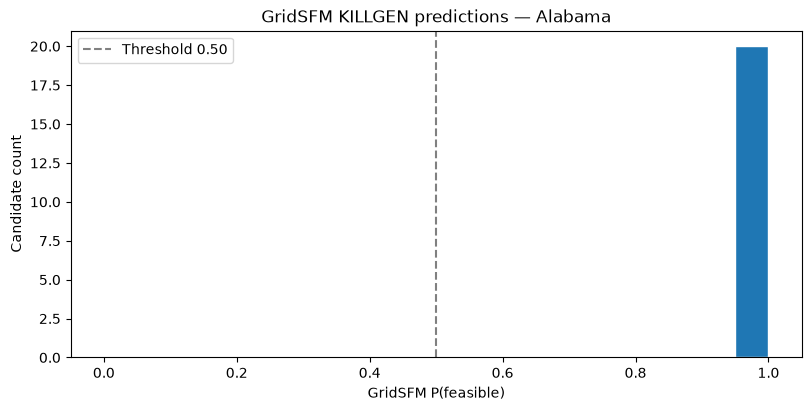

In [5]:
fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
ax.hist(model_probs,bins=np.linspace(0,1,21),edgecolor="white")
ax.axvline(MODEL_THRESHOLD,ls="--",color="gray",label=f"Threshold {MODEL_THRESHOLD:.2f}")
ax.set(xlabel="GridSFM P(feasible)",ylabel="Candidate count",
       title=f"GridSFM KILLGEN predictions — {DATASET_LABEL}")
ax.legend();fig.savefig(EXPLAIN_ROOT/"model_feasibility_histogram.png",dpi=180,bbox_inches="tight")
plt.show()


## 5. Easily select feasible/infeasible candidates

The dropdowns appear when `ipywidgets` is available. Otherwise use `MANUAL_SCENARIO_INDEX` in the next section. You can filter by model prediction, confidence, proximity to threshold, or outage count; **the Julia label is not used here**.


In [6]:
FILTERS=["All candidates","Predicted feasible","Predicted infeasible",
         "High confidence feasible (P>=0.9)","High confidence infeasible (P<=0.1)",
         "Near threshold (0.4<=P<=0.6)","Most generators off"]

def matches_filter(row,selection):
    p=row["gridsfm_p_feasible"]
    if selection=="Predicted feasible":return p>=MODEL_THRESHOLD
    if selection=="Predicted infeasible":return p<MODEL_THRESHOLD
    if selection.startswith("High confidence feasible"):return p>=0.9
    if selection.startswith("High confidence infeasible"):return p<=0.1
    if selection.startswith("Near threshold"):return 0.4<=p<=0.6
    if selection=="Most generators off":return row["n_generators_off"]==max(n_killed)
    return True

def describe_candidate(r):
    return (f"#{r['candidate_index']:04d} | iter {r['iteration']} sample {r['scenario']} | "
            f"P(feasible)={r['gridsfm_p_feasible']:.4f} | "
            f"{r['model_category']} | OFF: {r['generator_ids_killed']}")

try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE=True
except ImportError:
    WIDGETS_AVAILABLE=False

if WIDGETS_AVAILABLE:
    FILTER_WIDGET=widgets.Dropdown(options=FILTERS,value="All candidates",description="Filter:",layout=widgets.Layout(width="450px"))
    CANDIDATE_WIDGET=widgets.Dropdown(description="Candidate:",layout=widgets.Layout(width="850px"))
    def refresh_candidates(*args):
        eligible=[r for r in model_rows if matches_filter(r,FILTER_WIDGET.value)]
        CANDIDATE_WIDGET.options=[(describe_candidate(r),int(r["candidate_index"])) for r in eligible]
        if not eligible: print("No candidates match the selected filter")
    FILTER_WIDGET.observe(refresh_candidates,names="value")
    refresh_candidates()
    display(FILTER_WIDGET,CANDIDATE_WIDGET)
else:
    print("ipywidgets unavailable: use MANUAL_SCENARIO_INDEX in the next cell")
print("First candidates:")
for r in model_rows[:min(12,len(model_rows))]:print("  ",describe_candidate(r))


ipywidgets unavailable: use MANUAL_SCENARIO_INDEX in the next cell
First candidates:
   #0000 | iter 1 sample 1 | P(feasible)=0.9999 | Predicted feasible | OFF: 58
   #0001 | iter 1 sample 2 | P(feasible)=0.9999 | Predicted feasible | OFF: 21,54
   #0002 | iter 2 sample 1 | P(feasible)=0.9999 | Predicted feasible | OFF: 40
   #0003 | iter 2 sample 2 | P(feasible)=0.9999 | Predicted feasible | OFF: 44
   #0004 | iter 3 sample 1 | P(feasible)=0.9999 | Predicted feasible | OFF: 28
   #0005 | iter 3 sample 2 | P(feasible)=0.9999 | Predicted feasible | OFF: 49,21
   #0006 | iter 4 sample 1 | P(feasible)=0.9998 | Predicted feasible | OFF: 18,7
   #0007 | iter 4 sample 2 | P(feasible)=1.0000 | Predicted feasible | OFF: 40,16
   #0008 | iter 5 sample 1 | P(feasible)=0.9999 | Predicted feasible | OFF: 24
   #0009 | iter 5 sample 2 | P(feasible)=0.9999 | Predicted feasible | OFF: 18
   #0010 | iter 6 sample 1 | P(feasible)=0.9999 | Predicted feasible | OFF: 39,18
   #0011 | iter 6 sample 2 | P(f

## 6. Activate the selected candidate and specify the predicted class to explain


In [7]:
MANUAL_SCENARIO_INDEX=0
EXPLANATION_TARGET="predicted"   # "predicted", "feasible", "infeasible"
assert EXPLANATION_TARGET in ("predicted","feasible","infeasible")
if WIDGETS_AVAILABLE:
    if CANDIDATE_WIDGET.value is None:
        raise ValueError("Select a candidate in the dropdown (or filter differently)")
    SCENARIO_INDEX=int(CANDIDATE_WIDGET.value)
else:
    SCENARIO_INDEX=int(MANUAL_SCENARIO_INDEX)
if not 0<=SCENARIO_INDEX<len(candidates):raise IndexError(SCENARIO_INDEX)
selected_row=model_rows[SCENARIO_INDEX]
chosen_ids=candidate_killed_ids(SCENARIO_INDEX)
p_selected=float(model_probs[SCENARIO_INDEX])
TARGET_CLASS=("feasible" if p_selected>=MODEL_THRESHOLD else "infeasible") if EXPLANATION_TARGET=="predicted" else EXPLANATION_TARGET
p_selected_target=p_selected if TARGET_CLASS=="feasible" else 1-p_selected
p_original_target=p_original if TARGET_CLASS=="feasible" else 1-p_original
EXPLAIN_DIR=EXPLAIN_ROOT/f"candidate_{SCENARIO_INDEX:05d}"
EXPLAIN_DIR.mkdir(parents=True,exist_ok=True)
print("Selected candidate:",describe_candidate(selected_row))
print(f"Explaining GridSFM P({TARGET_CLASS})")
print("Original target probability:",p_original_target,"| candidate:",p_selected_target)


Selected candidate: #0000 | iter 1 sample 1 | P(feasible)=0.9999 | Predicted feasible | OFF: 58
Explaining GridSFM P(feasible)
Original target probability: 0.9999414682388306 | candidate: 0.9999388456344604


## 7. Visualize the selected outages and GridSFM verdict


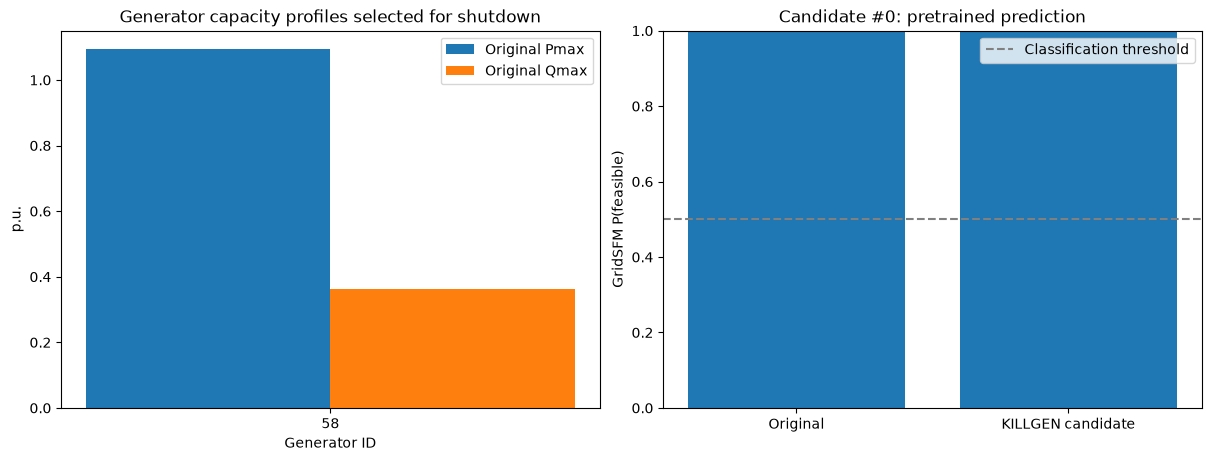

In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
xs=np.arange(len(chosen_ids))
axes[0].bar(xs-.18,[float(data["gen"][gid]["pmax"]) for gid in chosen_ids],width=.36,label="Original Pmax")
axes[0].bar(xs+.18,[float(data["gen"][gid]["qmax"]) for gid in chosen_ids],width=.36,label="Original Qmax")
axes[0].set_xticks(xs,[str(gid) for gid in chosen_ids]);axes[0].set(title="Generator capacity profiles selected for shutdown",xlabel="Generator ID",ylabel="p.u.")
axes[0].legend()
axes[1].bar(["Original", "KILLGEN candidate"],[p_original,p_selected])
axes[1].axhline(MODEL_THRESHOLD,color="gray",ls="--",label="Classification threshold")
axes[1].set(ylim=(0,1),ylabel="GridSFM P(feasible)",title=f"Candidate #{SCENARIO_INDEX}: pretrained prediction")
axes[1].legend()
fig.savefig(EXPLAIN_DIR/"00_generator_outages_and_model_probability.png",dpi=180,bbox_inches="tight")
plt.show()


## 8. Generator-level **exact SHAP** for the selected outages

Each feature is a binary generator shutdown: `0` means online (original grid) and `1` means offline (generator node/link removed). The baseline has all generators online; the full coalition is the selected outage scenario.

Since your KILLGEN policy switches off at most **three generators**, we can calculate the **exact Shapley values** using only `2^3 = 8` GridSFM model evaluations—no approximation, arbitrary group splitting, or heavy Kernel SHAP sampling. This is mathematically SHAP and is **more accurate and efficient** than running Captum KernelShap 128 times for 1–3 generators. It also handles the common single-generator outage directly.

In [9]:
from itertools import combinations
from math import factorial

num_features=len(chosen_ids)
assert 1<=num_features<=3, "Exact KILLGEN SHAP is configured for 1–3 outages"

# Model outcome for every subset of the generators switched off in the candidate.
coalition_value={}
for size in range(num_features+1):
    for subset in combinations(range(num_features),size):
        off=[chosen_ids[j] for j in subset]
        p=model_p_feasible(off)
        coalition_value[subset]=p if TARGET_CLASS=="feasible" else 1-p

shap_values=np.zeros(num_features,dtype=np.float64)
for j in range(num_features):
    other=[k for k in range(num_features) if k!=j]
    for size in range(num_features):
        for subset in combinations(other,size):
            subset=tuple(sorted(subset))
            subset_with_j=tuple(sorted(subset+(j,)))
            coefficient=factorial(size)*factorial(num_features-size-1)/factorial(num_features)
            shap_values[j]+=coefficient*(coalition_value[subset_with_j]-coalition_value[subset])

# SHAP efficiency holds exactly (within floating-point tolerance).
model_difference=coalition_value[tuple(range(num_features))]-coalition_value[()]
np.testing.assert_allclose(shap_values.sum(),model_difference,atol=2e-6,rtol=1e-5)
print("GridSFM P(target) difference from original:",model_difference)
print("Exact sum of generator SHAP contributions:",shap_values.sum())
print("Positive SHAP -> switching off that generator raises the model's target-class probability.")

GridSFM P(target) difference from original: -2.6226043701171875e-06
Exact sum of generator SHAP contributions: -2.6226043701171875e-06
Positive SHAP -> switching off that generator raises the model's target-class probability.


Generator-level SHAP rankings (pretrained model, NOT solver causality):
{'generator_id': '58', 'bus_id': '363', 'bus_name': 'BUS_363', 'original_pmax': 1.0954872749999913, 'original_qmax': 0.36151080074999714, 'original_gen_status': 1, 'candidate_gen_status': 0, 'shap': -2.6226043701171875e-06, 'abs_shap': 2.6226043701171875e-06}


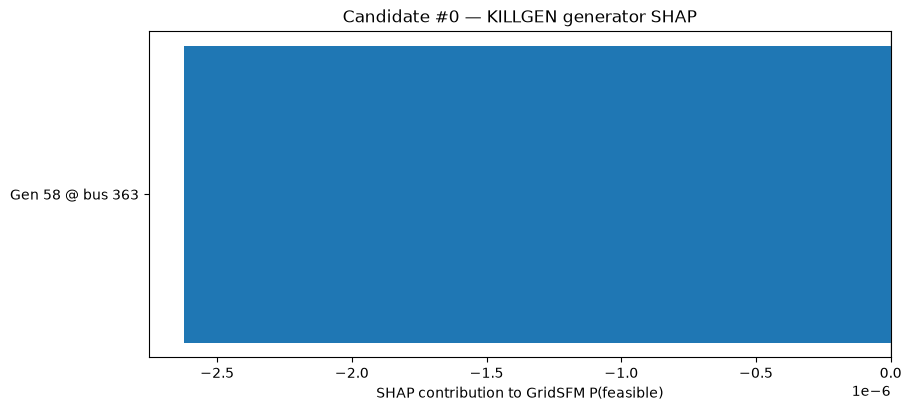

In [10]:
generator_rows=[]
for k,gid in enumerate(chosen_ids):
    gen=data["gen"][str(gid)]
    bid=str(gen.get("gen_bus",""))
    generator_rows.append(dict(generator_id=str(gid),bus_id=bid,
        bus_name=str(data.get("bus",{}).get(bid,{}).get("name","")),
        original_pmax=float(gen.get("pmax",0.)),original_qmax=float(gen.get("qmax",0.)),
        original_gen_status=1,candidate_gen_status=0,
        shap=float(shap_values[k]),abs_shap=float(abs(shap_values[k]))))
generator_rows.sort(key=lambda row:row["abs_shap"],reverse=True)
print("Generator-level SHAP rankings (pretrained model, NOT solver causality):")
for r in generator_rows:print(r)
fig,ax=plt.subplots(figsize=(9,max(4,0.7*len(generator_rows)+1)),constrained_layout=True)
ys=np.arange(len(generator_rows))
ax.barh(ys,[r["shap"] for r in generator_rows])
ax.set_yticks(ys,[f"Gen {r['generator_id']} @ bus {r['bus_id']}" for r in generator_rows])
ax.invert_yaxis();ax.axvline(0,color="gray",lw=1)
ax.set(xlabel=f"SHAP contribution to GridSFM P({TARGET_CLASS})",
       title=f"Candidate #{SCENARIO_INDEX} — KILLGEN generator SHAP")
fig.savefig(EXPLAIN_DIR/"01_generator_killgen_shap.png",dpi=180,bbox_inches="tight")
plt.show()


## 9. Export model scores and selected generator explanation


In [11]:
def write_csv(path, rows):
    if not rows:return
    with Path(path).open("w",newline="",encoding="utf-8") as f:
        writer=csv.DictWriter(f,fieldnames=list(rows[0]))
        writer.writeheader();writer.writerows(rows)

write_csv(EXPLAIN_DIR/"generator_killgen_shap.csv",generator_rows)
summary=dict(dataset=DATASET_NAME,candidate_index=int(SCENARIO_INDEX),
             iteration=int(selected_row["iteration"]),scenario=int(selected_row["scenario"]),
             gridsfm_p_feasible=float(p_selected),gridsfm_verdict=selected_row["model_category"],
             explanation_target=TARGET_CLASS,original_target_probability=float(p_original_target),
             selected_target_probability=float(p_selected_target),
             model_probability_difference=float(p_selected_target-p_original_target),
             shap_sum=float(shap_values.sum()),
             generator_ids_off=chosen_ids,source_case_sha256=CASE_SHA256,
             checkpoint=str(CHECKPOINT_PATH),pyg_graph=str(PYG_PATH))
with (EXPLAIN_DIR/"explanation_summary.json").open("w",encoding="utf-8") as f:
    json.dump(summary,f,indent=2)
print("All candidate model predictions:",EXPLAIN_ROOT/"pretrained_model_predictions.csv")
print("Candidate SHAP result:",EXPLAIN_DIR)


All candidate model predictions: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_killgen/alabama/gridsfm_pretrained_killgen_generator_shap/pretrained_model_predictions.csv
Candidate SHAP result: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_killgen/alabama/gridsfm_pretrained_killgen_generator_shap/candidate_00000


## Interpretation and limitations

- Julia's AC-OPF verifier is used only for **Gaussian sampling** in Notebook 1. It is **not** the SHAP label or explanation target.
- GridSFM supplies the **predicted** feasibility probability. A score above the configured 0.5 threshold is classified as feasible.
- Generator SHAP explains the effect of **removing generator nodes and links** on the model's predicted class probability, compared with the original graph. It does not identify a bus's load and it does not prove the physical cause of AC-OPF infeasibility.
- All explanations cover **only the generators switched off in the selected candidate**, and may depend on interactions among them.
- Most selected scenarios turn off only **one generator** (70% by configuration); in that case the single SHAP score equals the model probability change. Select a 2- or 3-generator outage to study interactions.
- If your baseline PyG graph has different generator IDs or capacities from the raw PowerModels case, **do not override the safety checks without correcting the graph**.
- For KILLGEN, turning off generators changes graph topology (generator nodes/links) rather than modifying `[Pmax,Qmax]` feature values.
